In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re


---
# **Data Inspection**

In [2]:
df=pd.read_csv('/run/media/haroon/Local Disk (D:)/Github/Artificial-Intelligence-Labs/Machine Learning/Used Car Price Predictor/data/pakwheels_raw.csv')
df.head()

,title,price_pkr,city,year,mileage_km,fuel,engine_cc,transmission,url,scraped_at
0,Suzuki Alto 2009 for Sale 7/10,1850000.0,Rawalpindi,2009,203759,Petrol,660.0,Automatic,https://www.pakwheels.com/used-cars/suzuki-alt...,2026-11-21T05:25:29+00:00
1,Mercedes Benz E Class 5th (W213) Generation 20...,42000000.0,Lahore,2023,8500,Petrol,1500.0,Automatic,https://www.pakwheels.com/used-cars/mercedes-b...,2026-11-21T05:25:29+00:00
2,Toyota Land Cruiser 2023 ZX Gasoline 3.5L for ...,62500000.0,Lahore,2023,13000,Petrol,3500.0,Automatic,https://www.pakwheels.com/used-cars/toyota-lan...,2026-11-21T05:25:29+00:00
3,Mercedes Benz E Class 2024 E200 for Sale,50000000.0,Lahore,2024,11500,Petrol,2000.0,Automatic,https://www.pakwheels.com/used-cars/mercedes-b...,2026-11-21T05:25:29+00:00
4,Mercedes Benz E Class 2024 E200 for Sale,50500000.0,Lahore,2024,9600,Petrol,2000.0,Automatic,https://www.pakwheels.com/used-cars/mercedes-b...,2026-11-21T05:25:29+00:00


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2115 entries, 0 to 2114
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         2115 non-null   str    
 1   price_pkr     2076 non-null   float64
 2   city          2115 non-null   str    
 3   year          2115 non-null   int64  
 4   mileage_km    2115 non-null   int64  
 5   fuel          2085 non-null   str    
 6   engine_cc     2092 non-null   float64
 7   transmission  2115 non-null   str    
 8   url           2115 non-null   str    
 9   scraped_at    2115 non-null   str    
dtypes: float64(2), int64(2), str(6)
memory usage: 165.4 KB


In [4]:
df.isna().sum()

title            0
price_pkr       39
city             0
year             0
mileage_km       0
fuel            30
engine_cc       23
transmission     0
url              0
scraped_at       0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

---
# **Data Cleaning**

In [ ]:
df=df.dropna(subset=['price_pkr'])
df=df[df['price_pkr']>0].copy()


In [ ]:
df['fuel']=df['fuel'].fillna('Petrol') # df['Fuel'].mode() : is Petrol
df['engine_cc']=df['engine_cc'].fillna(df['engine_cc'].median())


In [23]:
df.isna().sum()

title           0
price_pkr       0
city            0
year            0
mileage_km      0
fuel            0
engine_cc       0
transmission    0
url             0
scraped_at      0
dtype: int64

---
# **Feature Engineering**

In [24]:
columns = [
    "title",
    "year",
    "mileage_km",
    "engine_cc",
    "fuel",
    "transmission",
    "city",
    "price_pkr"
]

df=df[columns]
df.head()

,title,year,mileage_km,engine_cc,fuel,transmission,city,price_pkr
0,Suzuki Alto 2009 for Sale 7/10,2009,203759,660.0,Petrol,Automatic,Rawalpindi,1850000.0
1,Mercedes Benz E Class 5th (W213) Generation 20...,2023,8500,1500.0,Petrol,Automatic,Lahore,42000000.0
2,Toyota Land Cruiser 2023 ZX Gasoline 3.5L for ...,2023,13000,3500.0,Petrol,Automatic,Lahore,62500000.0
3,Mercedes Benz E Class 2024 E200 for Sale,2024,11500,2000.0,Petrol,Automatic,Lahore,50000000.0
4,Mercedes Benz E Class 2024 E200 for Sale,2024,9600,2000.0,Petrol,Automatic,Lahore,50500000.0


In [ ]:
df['title'].head(20).to_string(index=False)

                    Suzuki Alto 2009 for Sale 7/10
Mercedes Benz E Class 5th (W213) Generation 202...
Toyota Land Cruiser 2023 ZX Gasoline 3.5L for Sale
          Mercedes Benz E Class 2024 E200 for Sale
          Mercedes Benz E Class 2024 E200 for Sale
                     Suzuki Alto 2024 VXR for Sale
            JAC T9 2025 Frison RWD for Sale 9.7/10
            Toyota Corolla 2013 Altis 1.6 for Sale
                   Suzuki Baleno 2005 JXR for Sale
     Toyota Yaris 2026 GLI CVT 1.3 for Sale 9.8/10
            Mitsubishi Pajero 2017 GR 3.0 for Sale
                      Jetour T2 2026 PHEV for Sale
                  DFSK Glory 580 2022 Pro for Sale
Toyota Corolla 2015 GLi Automatic 1.3 VVTi for ...
           Suzuki Mehran 2017 VXR Euro II for Sale
Honda City 5th (GM2) Generation 2018 Aspire Pro...
        Toyota Corolla 2019 XLi Automatic for Sale
                  Suzuki Cultus 2011 VXRi for Sale
             United Bravo 2019 Base Grade for Sale
           Honda Civic 2002 VTi

In [ ]:
df['title'].value_counts().head(20)

title
Honda Civic 2018 Oriel 1.8 i-VTEC CVT for Sale                                  18
Suzuki Mehran 2018 VXR Euro II for Sale                                         13
Honda Civic 2017 Oriel 1.8 i-VTEC CVT for Sale                                  13
Suzuki Alto 2024 VXR for Sale                                                   11
Suzuki Cultus 2007 VXR for Sale                                                 11
Toyota Corolla 2011 GLi 1.3 VVTi for Sale                                       10
Jaecoo J5 2026 Premium for Sale                                                  9
Suzuki Mehran 2017 VXR Euro II for Sale                                          8
Honda Civic 8th (FD) Generation 2008 VTi Oriel Prosmatec 1.8 i-VTEC for Sale     8
Toyota Raize 2020 Z for Sale                                                     8
Toyota Yaris 2026 GLI CVT 1.3 for Sale                                           7
Suzuki Alto 2022 VXR for Sale                                                    

In [28]:


MAKE_ALIASES = {
    "Mercedes Benz": "Mercedes Benz",
    "Land Rover": "Land Rover",
    "Great Wall": "Great Wall",
    "Alfa Romeo": "Alfa Romeo",
    "Toyota": "Toyota",
    "Honda": "Honda",
    "Suzuki": "Suzuki",
    "Hyundai": "Hyundai",
    "Kia": "Kia",
    "Mitsubishi": "Mitsubishi",
    "Nissan": "Nissan",
    "DFSK": "DFSK",
    "JAC": "JAC",
    "Jetour": "Jetour",
    "Jaecoo": "Jaecoo",
    "United": "United",
    "Changan": "Changan",
    "Haval": "Haval",
    "MG": "MG",
    "BMW": "BMW",
    "Audi": "Audi",
    "BYD": "BYD",
}

KNOWN_MODELS = {
    "Toyota": [
        "Land Cruiser", "Corolla", "Yaris",
        "Raize", "Fortuner", "Hilux", "Aqua",
        "Prius", "Vitz", "Passo", "Camry"
    ],
    "Honda": [
        "Civic", "City", "BR-V", "HR-V",
        "Accord", "Vezel", "Fit"
    ],
    "Suzuki": [
        "Wagon R", "Alto", "Mehran",
        "Cultus", "Swift", "Baleno",
        "Bolan", "Every", "Jimny"
    ],
    "Mercedes Benz": [
        "E Class", "C Class", "S Class",
        "A Class", "GLA", "GLC", "GLE"
    ],
    "Mitsubishi": ["Pajero", "Lancer"],
    "JAC": ["T9"],
    "Jetour": ["T2"],
    "DFSK": ["Glory 580"],
    "United": ["Bravo", "Alpha"],
    "Jaecoo": ["J5", "J7"],
}


def clean_title(title):
    title = str(title).strip()

    # Remove rating at the end, e.g. 9.7/10
    title = re.sub(
        r"\s+\d+(?:\.\d+)?/10\s*$",
        "",
        title
    )

    # Remove 'for Sale'
    title = re.sub(
        r"\s+for Sale\b",
        "",
        title,
        flags=re.IGNORECASE
    )

    # Remove generation descriptions
    title = re.sub(
        r"\b\d+(?:st|nd|rd|th)\s+"
        r"(?:\([^)]*\)\s+)?Generation\b",
        "",
        title,
        flags=re.IGNORECASE
    )

    return " ".join(title.split())


def extract_car_features(title, year):
    title = clean_title(title)

    make = "Unknown"
    model = "Unknown"
    variant = "Unknown"

    # Match longest manufacturer first
    for candidate in sorted(
        MAKE_ALIASES,
        key=len,
        reverse=True
    ):
        if re.match(
            rf"^{re.escape(candidate)}(?:\s|$)",
            title,
            flags=re.IGNORECASE
        ):
            make = MAKE_ALIASES[candidate]
            title = title[len(candidate):].strip()
            break

    # Match known models for the manufacturer
    for candidate in sorted(
        KNOWN_MODELS.get(make, []),
        key=len,
        reverse=True
    ):
        if re.match(
            rf"^{re.escape(candidate)}(?:\s|$)",
            title,
            flags=re.IGNORECASE
        ):
            model = candidate
            title = title[len(candidate):].strip()
            break

    # Fallback for models not in the dictionary
    if model == "Unknown" and make != "Unknown":
        match = re.match(
            r"^(.*?)(?=\s+(?:19|20)\d{2}\b|$)",
            title
        )
        if match and match.group(1).strip():
            model = match.group(1).strip()
            title = title[len(model):].strip()

    # Remove year (already present in the dataset)
    title = re.sub(
        rf"\b{int(year)}\b",
        "",
        title,
        count=1
    ).strip()

    if title:
        variant = title

    return pd.Series({
        "make": make,
        "model": model,
        "variant": variant
    })


# Apply feature extraction
df[["make", "model", "variant"]] = df.apply(
    lambda row: extract_car_features(
        row["title"],
        row["year"]
    ),
    axis=1
)

In [30]:
print(
    df[
        ["title", "make", "model", "variant"]
    ].head(20).to_string(index=False)
)

                                                                         title          make        model                     variant
                                                Suzuki Alto 2009 for Sale 7/10        Suzuki         Alto                     Unknown
Mercedes Benz E Class 5th (W213) Generation 2023 E 200 Sport BSG 1.5L for Sale Mercedes Benz      E Class        E 200 Sport BSG 1.5L
                            Toyota Land Cruiser 2023 ZX Gasoline 3.5L for Sale        Toyota Land Cruiser            ZX Gasoline 3.5L
                                      Mercedes Benz E Class 2024 E200 for Sale Mercedes Benz      E Class                        E200
                                      Mercedes Benz E Class 2024 E200 for Sale Mercedes Benz      E Class                        E200
                                                 Suzuki Alto 2024 VXR for Sale        Suzuki         Alto                         VXR
                                        JAC T9 2025 Frison RWD

In [31]:
print("Unknown makes:",
      (df["make"] == "Unknown").sum())

print("Unknown models:",
      (df["model"] == "Unknown").sum())

print("\nTop manufacturers:")
print(df["make"].value_counts().head(20))

print("\nTop models:")
print(df["model"].value_counts().head(20))

Unknown makes: 133
Unknown models: 133

Top manufacturers:
make
Toyota           573
Suzuki           542
Honda            447
Unknown          133
Kia               69
Hyundai           59
Nissan            49
Changan           42
Haval             30
MG                26
Mitsubishi        25
Mercedes Benz     24
Jaecoo            19
Audi              11
Jetour             7
BMW                7
BYD                6
DFSK               4
JAC                2
United             1
Name: count, dtype: int64

Top models:
model
Corolla         270
Civic           211
City            152
Alto            136
Unknown         133
Cultus          116
Mehran          105
Wagon R          56
Yaris            50
Swift            42
Vitz             34
Sportage         33
Land Cruiser     32
Passo            30
H6               24
Raize            24
HS               22
Tucson           22
Fortuner         21
Hilux            20
Name: count, dtype: int64


In [32]:
suspicious = df[
    df["model"].str.split().str.len() > 3
]

print(
    suspicious[["title", "model"]]
    .head(20)
    .to_string(index=False)
)

Empty DataFrame
Columns: [title, model]
Index: []


In [33]:
df["car_age"] = 2026 - df["year"]

In [37]:
unknown_cars = df[df["make"] == "Unknown"]

print(
    unknown_cars["title"]
    .value_counts()
    .head(50)
    .to_string()
)
unknown_cars = df[df["make"] == "Unknown"].copy()

unknown_cars["possible_make"] = (
    unknown_cars["title"]
    .str.split()
    .str[0]
)

print(
    unknown_cars["possible_make"]
    .value_counts()
    .head(30)
)


title
Deepal S05 2026 REEV Premium for Sale             6
Daihatsu Cuore 2009 CX Eco for Sale               3
Proton Saga 2022 1.3L Ace A/T for Sale            3
Chery Tiggo 7 2026 Premium PHEV FWD for Sale      2
FAW V2 2015 VCT-i for Sale                        2
Peugeot 2008 2022 Allure for Sale                 2
Daihatsu Mira 2012 ES for Sale                    2
Daihatsu Mira 2012 G SA for Sale                  2
Chery Q 2026 EV 400 for Sale                      2
Lexus UX 2021 300e for Sale                       2
Tank 500 2026 PHEV for Sale                       2
Tank 500 2026 HEV for Sale                        2
Daihatsu Mira 2016 X Memorial Edition for Sale    2
Daihatsu Mira 2011 for Sale                       2
Daihatsu Mira 2015 ES for Sale                    2
Daihatsu Mira 2023 X SA lll for Sale              2
Daihatsu Mira 2013 ES for Sale                    2
Daihatsu Hijet 2007 Special for Sale              1
Peugeot 2008 2023 Allure for Sale                 1
Daihat

In [38]:
MAKE_ALIASES.update({
    "Daihatsu": "Daihatsu",
    "Chery": "Chery",
    "Deepal": "Deepal",
    "FAW": "FAW",
    "Peugeot": "Peugeot",
    "Tank": "Tank",
    "Lexus": "Lexus",
    "Mazda": "Mazda",
    "Proton": "Proton",
    "Prince": "Prince",
    "Daewoo": "Daewoo",
    "Isuzu": "Isuzu",
    "Subaru": "Subaru",
    "Chrysler": "Chrysler",
    "Nevo": "Nevo",
    "JMEV": "JMEV",
    "JW": "JW",
    "Jeep": "Jeep",
    "Porsche": "Porsche",
    "Chevrolet": "Chevrolet",
    "Volkswagen": "Volkswagen",
})

MAKE_ALIASES.pop("JW", None)
MAKE_ALIASES["JW Forland"] = "JW Forland"

KNOWN_MODELS.update({
    "Daihatsu": [
        "Move Canbus", "Cuore", "Mira", "Hijet",
        "Copen", "Rocky", "Cast", "Move"
    ],
    "Deepal": ["S05"],
    "Chery": ["Tiggo 7", "Tiggo 8", "Q"],
    "FAW": ["V2"],
    "Peugeot": ["2008"],
    "Tank": ["500"],
    "Lexus": ["UX"],
    "Mazda": ["Scrum Van", "Carol"],
    "Proton": ["Saga"],
    "Prince": ["Pearl"],
    "Subaru": ["Stella"],
    "Chrysler": ["300 C"],
    "Nevo": ["Hunter"],
    "JMEV": ["EV3"],
    "JW Forland": ["Safari"],
    "Jeep": ["M 151"],
})

df[["make", "model", "variant"]] = df.apply(

    lambda row: extract_car_features(
        row["title"],
        row["year"]
    ),
    axis=1
)

In [39]:
print("Unknown makes:", (df["make"] == "Unknown").sum())
print("Unknown models:", (df["model"] == "Unknown").sum())

print("\nTop makes:")
print(df["make"].value_counts().head(20))

print("\nTop models:")
print(df["model"].value_counts().head(20))

Unknown makes: 0
Unknown models: 0

Top makes:
make
Toyota           573
Suzuki           542
Honda            447
Daihatsu          73
Kia               69
Hyundai           59
Nissan            49
Changan           42
Haval             30
MG                26
Mitsubishi        25
Mercedes Benz     24
Jaecoo            19
Audi              11
Jetour             7
Chery              7
BMW                7
Deepal             7
FAW                6
Peugeot            6
Name: count, dtype: int64

Top models:
model
Corolla         270
Civic           211
City            152
Alto            136
Cultus          116
Mehran          105
Wagon R          56
Yaris            50
Swift            42
Vitz             34
Sportage         33
Mira             33
Land Cruiser     32
Passo            30
H6               24
Raize            24
HS               22
Tucson           22
Fortuner         21
Hilux            20
Name: count, dtype: int64


In [40]:
brands_to_check = [
    "Daihatsu", "Deepal", "Chery",
    "Peugeot", "Tank", "Lexus",
    "JW Forland"
]

print(
    df[df["make"].isin(brands_to_check)]
    [["title", "make", "model", "variant"]]
    .head(30)
    .to_string(index=False)
)

                                         title     make       model            variant
  Chery Tiggo 7 2026 Premium PHEV FWD for Sale    Chery     Tiggo 7   Premium PHEV FWD
          Daihatsu Hijet 2007 Special for Sale Daihatsu       Hijet            Special
             Peugeot 2008 2023 Allure for Sale  Peugeot        2008             Allure
   Daihatsu Mira 2022 L SA III for Sale 9.8/10 Daihatsu        Mira           L SA III
             Peugeot 2008 2022 Allure for Sale  Peugeot        2008             Allure
           Daihatsu Cuore 2012 CX Eco for Sale Daihatsu       Cuore             CX Eco
Daihatsu Mira 2014 X Memorial Edition for Sale Daihatsu        Mira X Memorial Edition
      Peugeot 2008 2024 Allure for Sale 9.5/10  Peugeot        2008             Allure
           Daihatsu Copen 2016 Robe S for Sale Daihatsu       Copen             Robe S
                Daihatsu Mira 2012 ES for Sale Daihatsu        Mira                 ES
              Daihatsu Mira 2012 G SA for S

In [ ]:
df.to_csv("/run/media/haroon/Local Disk (D:)/Github/Artificial-Intelligence-Labs/Machine Learning/Used Car Price Predictor/data/pakwheels_featured.csv", index=False)

---
# **Exploratory Data Analysis**

Price distribution and expensive cars

count    2076.000000
mean       47.507938
std        59.519352
min         2.500000
25%        21.850000
50%        34.000000
75%        52.500000
max       785.000000
Name: price_lakh, dtype: float64


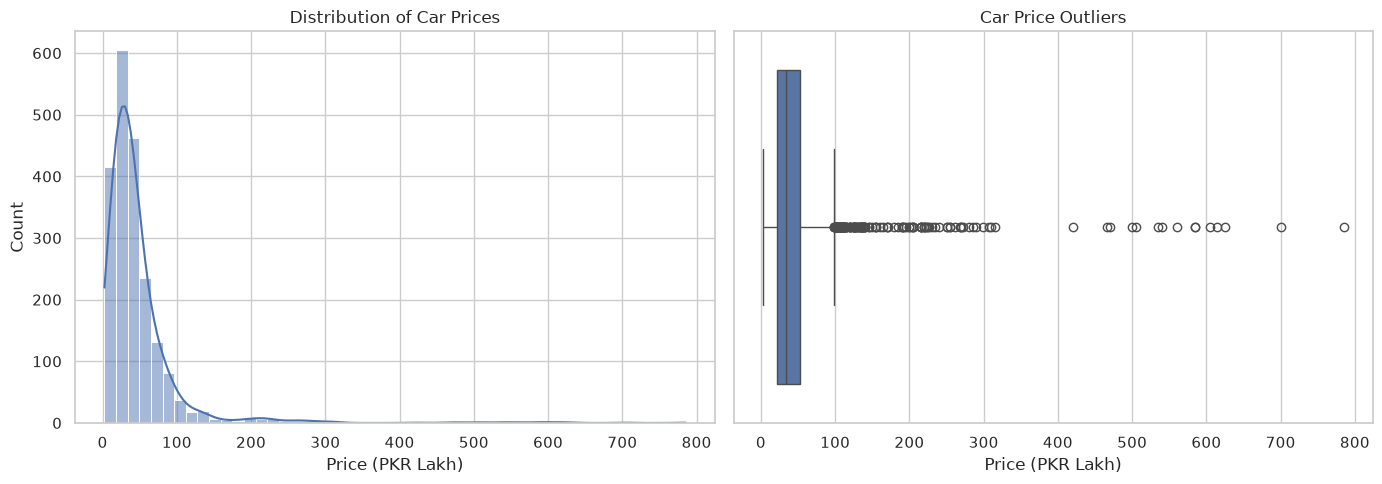


Top 10 most expensive cars:


,make,model,year,price_lakh
1573,Toyota,Land Cruiser,2023,785.0
1401,Toyota,Land Cruiser,2024,700.0
2,Toyota,Land Cruiser,2023,625.0
2096,Toyota,Land Cruiser,2023,614.0
1547,Lexus,LX,2018,605.0
241,Toyota,Land Cruiser,2023,585.0
1733,BMW,7 Series,2023,585.0
464,Toyota,Land Cruiser,2022,560.0
447,Toyota,Land Cruiser,2022,540.0
308,Toyota,Land Cruiser,2021,535.0


In [50]:



sns.set_theme(style="whitegrid")

# Convert PKR to lakh for easier visualization
df["price_lakh"] = df["price_pkr"] / 100_000

print(df["price_lakh"].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["price_lakh"],
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Car Prices")
axes[0].set_xlabel("Price (PKR Lakh)")

sns.boxplot(
    x=df["price_lakh"],
    ax=axes[1]
)
axes[1].set_title("Car Price Outliers")
axes[1].set_xlabel("Price (PKR Lakh)")

plt.tight_layout()
plt.show()

# Top 10 most expensive cars
print("\nTop 10 most expensive cars:")
display(
    df.nlargest(10, "price_pkr")[
        ["make", "model", "year", "price_lakh"]
    ]
)

Manufacturing year vs price

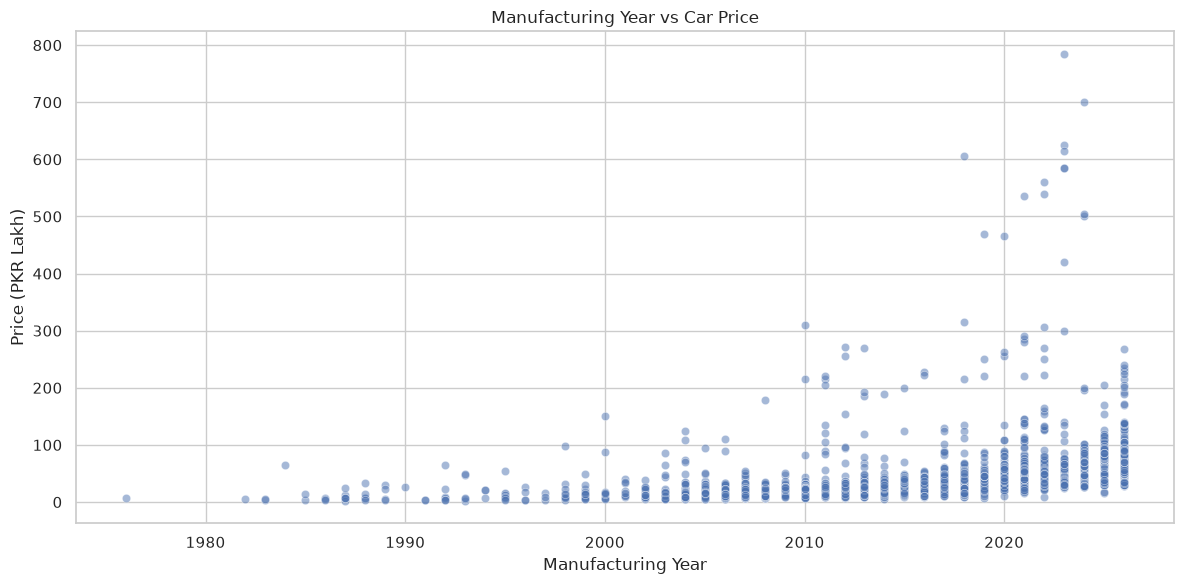

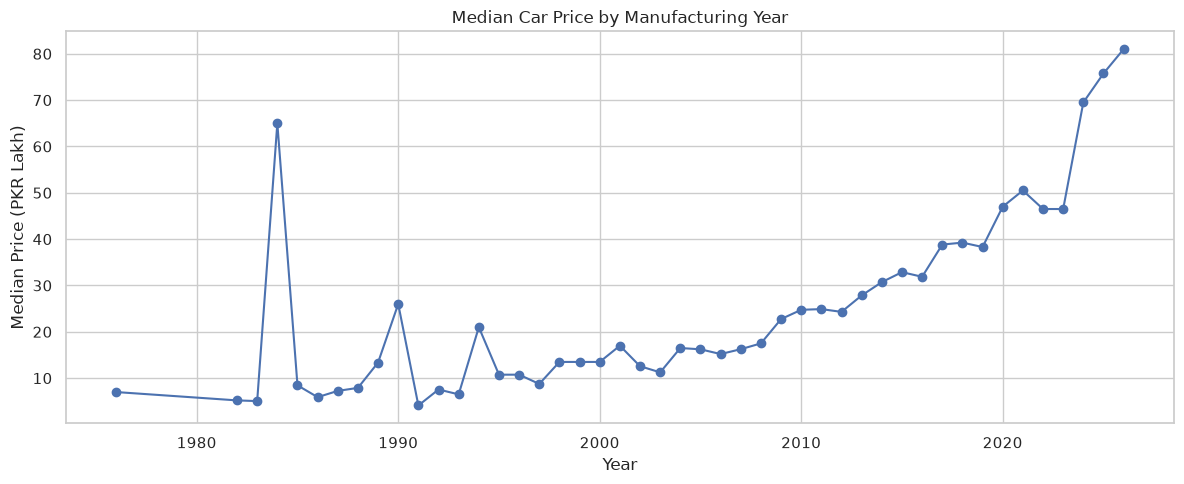

In [51]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="year",
    y="price_lakh",
    alpha=0.5
)

plt.title("Manufacturing Year vs Car Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Price (PKR Lakh)")
plt.tight_layout()
plt.show()

# Median price by year
year_prices = df.groupby("year")["price_lakh"].median()

plt.figure(figsize=(12, 5))
year_prices.plot(marker="o")

plt.title("Median Car Price by Manufacturing Year")
plt.xlabel("Year")
plt.ylabel("Median Price (PKR Lakh)")
plt.tight_layout()
plt.show()

Mileage vs price

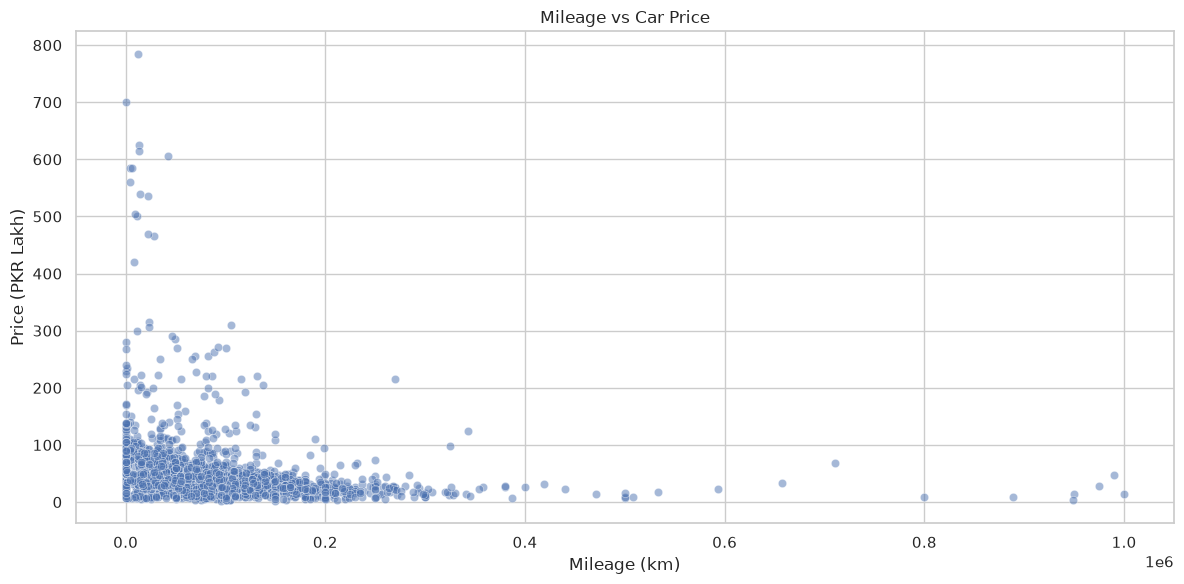

Mileage vs Price correlation: -0.239


In [52]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="mileage_km",
    y="price_lakh",
    alpha=0.5
)

plt.title("Mileage vs Car Price")
plt.xlabel("Mileage (km)")
plt.ylabel("Price (PKR Lakh)")
plt.tight_layout()
plt.show()

# Mileage-price correlation
correlation = df[
    ["mileage_km", "price_pkr"]
].corr().loc["mileage_km", "price_pkr"]

print(f"Mileage vs Price correlation: {correlation:.3f}")

Average and median prices by manufacturer/model

,count,mean,median
make,,,
Porsche,1,270.00,270.00
Tank,5,223.00,225.00
Lexus,4,285.00,212.00
Nevo,1,119.00,119.00
Jetour,7,102.00,114.00
Chrysler,1,110.00,110.00
Deepal,7,102.09,102.00
JAC,2,100.25,100.25
Haval,30,92.36,91.25


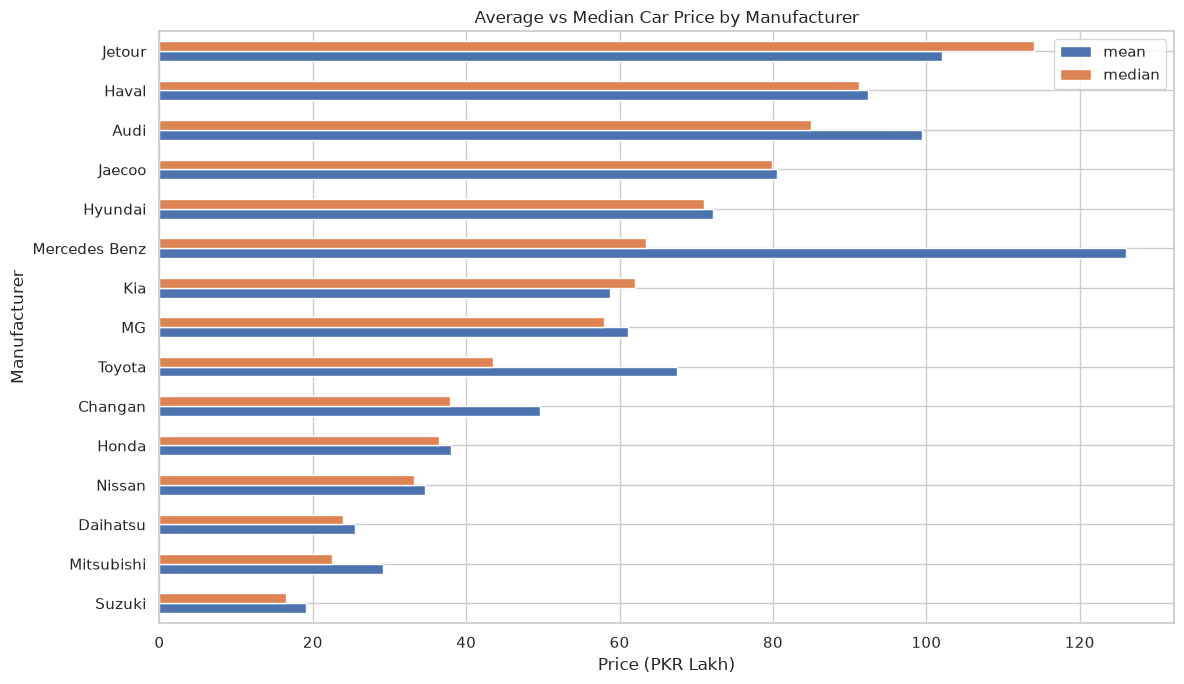

In [53]:
make_prices = (
    df.groupby("make")["price_lakh"]
    .agg(count="count", mean="mean", median="median")
    .sort_values("median", ascending=False)
)

display(make_prices.round(2))

# Top 15 makes by listing count
top_makes = df["make"].value_counts().head(15).index

make_subset = make_prices.loc[top_makes].sort_values("median")

make_subset[["mean", "median"]].plot(
    kind="barh",
    figsize=(12, 7)
)

plt.title("Average vs Median Car Price by Manufacturer")
plt.xlabel("Price (PKR Lakh)")
plt.ylabel("Manufacturer")
plt.tight_layout()
plt.show()

,make,model,count,mean,median
143,Tank,500,5,223.00,225.00
162,Toyota,Prado,20,211.92,224.50
157,Toyota,Land Cruiser,32,279.71,210.00
154,Toyota,Fortuner,21,145.12,138.00
156,Toyota,Hilux,20,106.88,117.50
36,Deepal,S05,7,102.09,102.00
39,Haval,H6,24,94.54,92.95
89,Mercedes Benz,E Class,17,161.71,90.00
61,Hyundai,Sonata,9,95.39,89.00
147,Toyota,C-HR,5,85.90,86.50


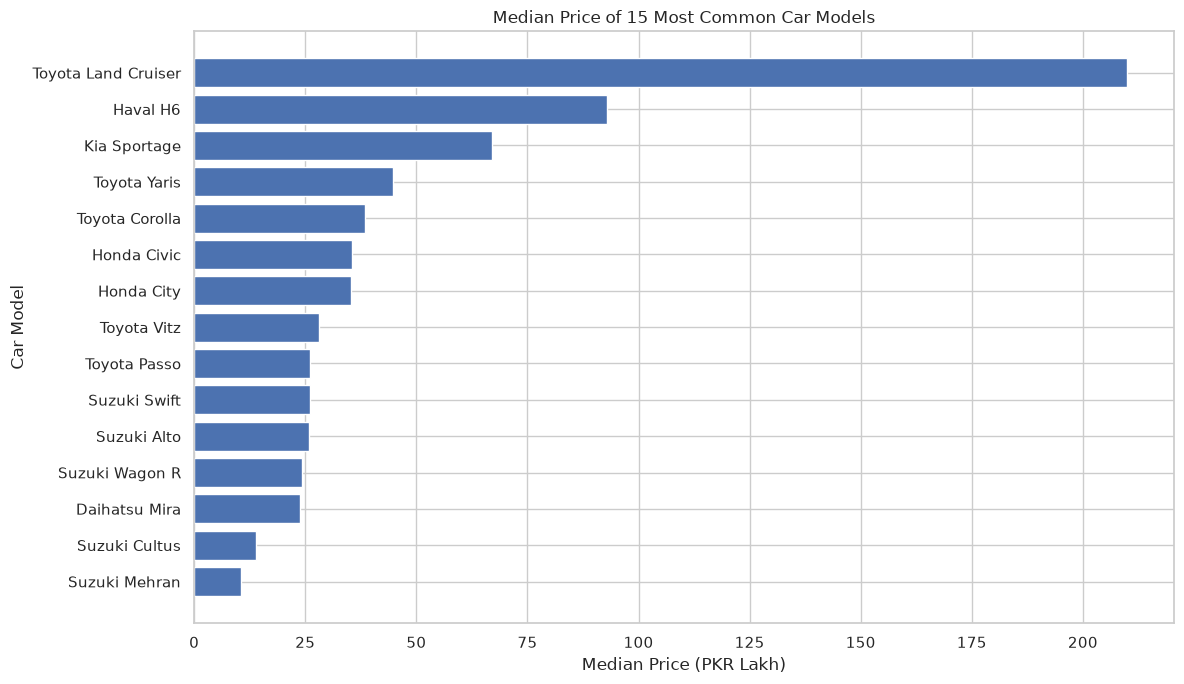

In [54]:
model_prices = (
    df.groupby(["make", "model"])["price_lakh"]
    .agg(count="count", mean="mean", median="median")
    .reset_index()
)

# Only include models with at least 5 listings
model_prices = model_prices[
    model_prices["count"] >= 5
]

display(
    model_prices.sort_values(
        "median", ascending=False
    ).head(20).round(2)
)

# Top 15 most common make/model combinations
top_models = (
    df.groupby(["make", "model"])
    .size()
    .nlargest(15)
    .index
)

model_subset = model_prices.set_index(
    ["make", "model"]
).reindex(top_models).dropna(subset=["median"])

model_subset = model_subset.sort_values("median")

labels = [
    f"{make} {model}"
    for make, model in model_subset.index
]

plt.figure(figsize=(12, 7))
plt.barh(labels, model_subset["median"])

plt.title("Median Price of 15 Most Common Car Models")
plt.xlabel("Median Price (PKR Lakh)")
plt.ylabel("Car Model")
plt.tight_layout()
plt.show()

In [55]:
# Diagnostic rules — not automatic deletion rules
suspicious = df[
    (df["mileage_km"] == 0) |
    (df["mileage_km"] > 500_000) |
    (df["year"] > 2027) |
    (df["year"] < 1980) |
    (df["engine_cc"] < 500) |
    (df["engine_cc"] > 6000)
]

print("Suspicious records:", len(suspicious))

display(
    suspicious[
        [
            "title", "year", "mileage_km",
            "engine_cc", "price_lakh"
        ]
    ].head(30)
)

Suspicious records: 13


,title,year,mileage_km,engine_cc,price_lakh
64,Hyundai Tucson 2021 FWD A/T GLS Sport for Sale,2021,710000,2000.0,69.00
75,Honda City 2006 i-DSI for Sale 4.7/10,2006,533279,1300.0,16.95
120,Toyota Corolla 9th (E120) Generation 2004 XLi ...,2004,592782,1300.0,23.00
121,Suzuki Cultus 2006 VXL for Sale,2006,888880,1000.0,8.80
235,KIA Picanto 2020 1.0 AT for Sale,2020,975000,1000.0,27.50
239,Audi A4 4th (B8) Generation 2009 1.8 TFSI for ...,2009,990000,1800.0,47.90
259,Suzuki Mehran 2008 VXR for Sale,2008,508000,800.0,8.50
316,Toyota Corolla 1976 for Sale,1976,100000,1800.0,7.00
599,Suzuki Alto 2022 VXL AGS for Sale,2022,657480,660.0,34.00
1621,Mitsubishi Pajero 1985 Exceed 2.5D for Sale,1985,1000000,2500.0,13.50


Correlation heatmap

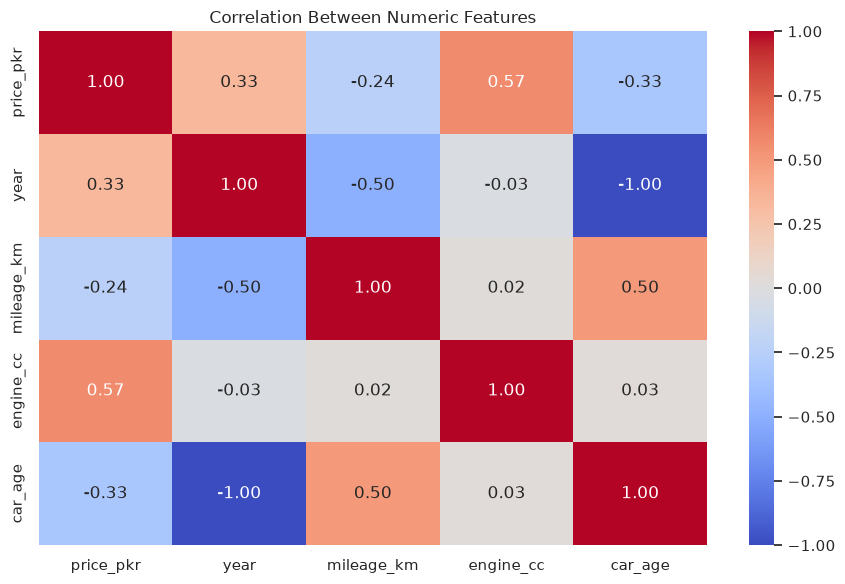

In [56]:
numeric_cols = [
    "price_pkr",
    "year",
    "mileage_km",
    "engine_cc"
]

# Add car_age if it exists
if "car_age" in df.columns:
    numeric_cols.append("car_age")

plt.figure(figsize=(9, 6))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Numeric Features")
plt.tight_layout()
plt.show()

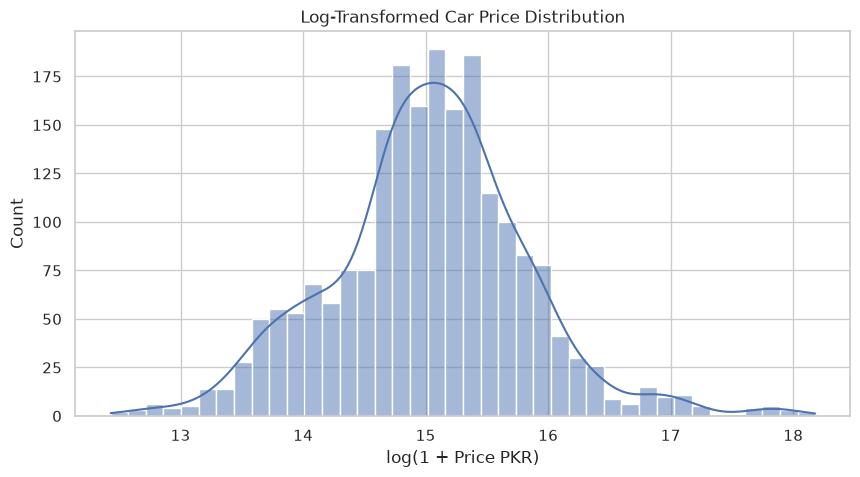

In [57]:
df["log_price"] = np.log1p(df["price_pkr"])

plt.figure(figsize=(10, 5))
sns.histplot(df["log_price"], bins=40, kde=True)

plt.title("Log-Transformed Car Price Distribution")
plt.xlabel("log(1 + Price PKR)")
plt.show()

In [58]:
df.head()

,title,year,mileage_km,engine_cc,fuel,transmission,city,price_pkr,make,model,variant,car_age,price_lakh,log_price
0,Suzuki Alto 2009 for Sale 7/10,2009,203759,660.0,Petrol,Automatic,Rawalpindi,1850000.0,Suzuki,Alto,Unknown,17,18.5,14.430697
1,Mercedes Benz E Class 5th (W213) Generation 20...,2023,8500,1500.0,Petrol,Automatic,Lahore,42000000.0,Mercedes Benz,E Class,E 200 Sport BSG 1.5L,3,420.0,17.553180
2,Toyota Land Cruiser 2023 ZX Gasoline 3.5L for ...,2023,13000,3500.0,Petrol,Automatic,Lahore,62500000.0,Toyota,Land Cruiser,ZX Gasoline 3.5L,3,625.0,17.950677
3,Mercedes Benz E Class 2024 E200 for Sale,2024,11500,2000.0,Petrol,Automatic,Lahore,50000000.0,Mercedes Benz,E Class,E200,2,500.0,17.727534
4,Mercedes Benz E Class 2024 E200 for Sale,2024,9600,2000.0,Petrol,Automatic,Lahore,50500000.0,Mercedes Benz,E Class,E200,2,505.0,17.737484


In [59]:
# Compare listing prices to the median for the same model
group_median = df.groupby(
    ["make", "model"]
)["price_pkr"].transform("median")

df["price_to_model_median"] = (
    df["price_pkr"] / group_median
)

suspicious_prices = df[
    (df["price_to_model_median"] > 3) |
    (df["price_to_model_median"] < 1/3)
]

display(
    suspicious_prices[
        ["title", "year", "price_pkr", "price_to_model_median"]
    ].sort_values("price_to_model_median", ascending=False)
    .head(20)
)

,title,year,price_pkr,price_to_model_median
1733,BMW 7 Series 2023 i7 xDrive60 M Sports for Sale,2023,58500000.0,12.061856
4,Mercedes Benz E Class 2024 E200 for Sale,2024,50500000.0,5.611111
3,Mercedes Benz E Class 2024 E200 for Sale,2024,50000000.0,5.555556
10,Mitsubishi Pajero 2017 GR 3.0 for Sale,2017,13000000.0,5.000000
1,Mercedes Benz E Class 5th (W213) Generation 20...,2023,42000000.0,4.666667
1302,Suzuki Khyber 1996 GA for Sale,1996,1750000.0,3.910615
1573,Toyota Land Cruiser 2023 GR Sport for Sale 9.9/10,2023,78500000.0,3.738095
960,Honda Civic 2023 for Sale 9.8/10,2023,12000000.0,3.380282
1401,Toyota Land Cruiser 2024 ZX Gasoline 3.5L for ...,2024,70000000.0,3.333333
277,Mercedes Benz E Class 5th (W213) Generation 20...,2023,29900000.0,3.322222


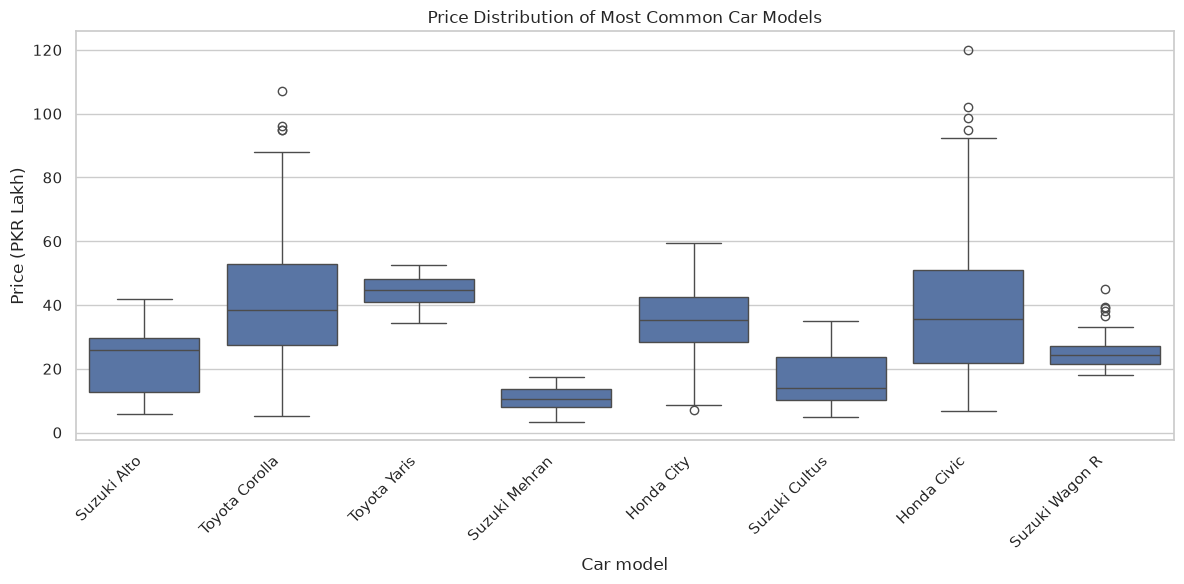

In [60]:
popular_models = (
    df.groupby(["make", "model"])
    .size()
    .nlargest(8)
    .index
)

df_popular = df[
    df.set_index(["make", "model"]).index.isin(popular_models)
].copy()

df_popular["car_model"] = (
    df_popular["make"] + " " + df_popular["model"]
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_popular,
    x="car_model",
    y="price_lakh"
)

plt.xticks(rotation=45, ha="right")
plt.title("Price Distribution of Most Common Car Models")
plt.xlabel("Car model")
plt.ylabel("Price (PKR Lakh)")
plt.tight_layout()
plt.show()

In [61]:
# Detect suspicious price outliers within similar models and years
df["year_group"] = (df["year"] // 5) * 5

group = df.groupby(["make", "model", "year_group"])["price_pkr"]

df["group_count"] = group.transform("count")
df["group_median"] = group.transform("median")
df["price_ratio"] = df["price_pkr"] / df["group_median"]

outliers = df[
    (df["group_count"] >= 5) &
    (
        (df["price_ratio"] > 2.5) |
        (df["price_ratio"] < 0.4)
    )
]

print("Suspicious outliers:", len(outliers))
display(outliers[["title", "year", "price_pkr", "price_ratio"]])

# Keep all records for now; do not remove legitimate expensive cars.
# Remove temporary columns before modeling.
df.drop(
    columns=["year_group", "group_count", "group_median", "price_ratio"],
    inplace=True
)

Suspicious outliers: 1


,title,year,price_pkr,price_ratio
1302,Suzuki Khyber 1996 GA for Sale,1996,1750000.0,3.763441


---
# **Train-Test Split**

In [ ]:
features = [
    "make",
    "model",
    "variant",
    "year",
    "mileage_km",
    "engine_cc",
    "fuel",
    "transmission",
    "city"
]

X = df[features].copy()
y = df["price_pkr"].copy()